# Figures and tables of the pkdgrav3 pipeline report

Every figure (`figures/*.pdf`) and generated table (`figures/tab_*.tex`) of `pkdgrav3_pipeline_report.tex` is made
here from the files in `data/` only. Run all cells (or
`jupyter nbconvert --to notebook --execute --inplace make_figures.ipynb`), then `latexmk -pdf pkdgrav3_pipeline_report.tex`.

The data files are reduced from the pawna runs by `extract_data.py` (catalogs too large for the repository):

| File | Content |
|---|---|
| `halo_routes_512.npz` | Rockstar catalogs of the 512^3 run, per input route and output: Mvir, Vmax histograms; matched-halo differences for pairs of routes |
| `ctrees_512.npz` | consistent-trees z = 0 host / subhalo mass histograms (pkc and raw routes) |
| `quantization_512.npz` | per-particle .pkc minus raw position and velocity (1% subsample, z = 0) |
| `routes_512.csv` | Rockstar wall time, peak memory, halo counts per route |
| `stages.csv`, `mem_*.tsv` | wall time and memory of every pipeline stage (128^3 and 512^3 runs) and validation step |
| `vahc_bug_128.npz` | density-Hessian eigenvalues at 3 and 5 Mpc/h before and after the fix (128^3 test) |

In [1]:
import glob, os
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
mpl.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.labelsize': 9, 'legend.fontsize': 7.5,
                     'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
                     'savefig.bbox': 'tight', 'lines.linewidth': 1.2})
os.makedirs('figures', exist_ok=True)
H = dict(np.load('data/halo_routes_512.npz'))
z = H['z']; nz = len(z); mb = H['mbins']; mc = np.sqrt(mb[1:] * mb[:-1]); dlm = np.diff(np.log10(mb))[0]
MP = 8.110260e7           # particle mass of the 512^3 / 50 Mpc/h run [Msun/h]
VOL = 50.0**3
C = {'pkc': 'C0', 'pkc2': 'C9', 'gad': 'C2', 'h5g': 'k', 'pkcsub': 'C3'}
LAB = {'pkc': 'pkc (native reader)', 'pkc2': 'pkc, 2nd run', 'gad': 'pkc$\\to$Gadget', 'h5g': 'raw (HDF5$\\to$Gadget)',
       'pkcsub': 'pkc 1%+3% subsample'}
PAIRLAB = {('pkc', 'h5g'): 'pkc vs raw (compression)', ('pkc', 'pkc2'): 'pkc vs pkc (Rockstar noise)',
           ('pkc', 'gad'): 'pkc vs pkc$\\to$Gadget (reader)', ('pkcsub', 'pkc'): '4% subsample vs pkc'}
PAIRC = {('pkc', 'h5g'): 'C3', ('pkc', 'pkc2'): '0.5', ('pkc', 'gad'): 'C2', ('pkcsub', 'pkc'): 'C1'}
routes = [r for r in C if f'hm_{r}_0' in H]
print('outputs z =', np.round(z, 3), '; routes:', routes)

def pair(A, B, i):
    k = f'pair_{A}_{B}_{i}_'
    if k + 'logM' not in H: return None
    return {n[len(k):]: H[n] for n in H if n.startswith(k)}

def binned(x, y, bins, f=np.nanmedian, nmin=10):
    out = np.full(len(bins) - 1, np.nan)
    idx = np.digitize(x, bins) - 1
    for b in range(len(bins) - 1):
        s = y[(idx == b) & np.isfinite(y)]
        if len(s) >= nmin: out[b] = f(s)
    return out
LB = np.arange(10, 14.01, 0.25); LC = 0.5 * (LB[1:] + LB[:-1])
MBIN = [(1e10, 1e11), (1e11, 1e12), (1e12, 1e13), (1e13, 1e16)]

outputs z = [3.   2.   1.   0.5  0.25 0.  ] ; routes: ['pkc', 'pkc2', 'gad', 'h5g', 'pkcsub']


## Figure: density-Hessian bug in `.vahc` (`lamH*_R5Mpch`)

snapshot 0 columns that differ: [np.str_('lamH1_R5Mpch'), np.str_('lamH2_R5Mpch'), np.str_('lamH3_R5Mpch')]  rms ratio: [0.61, 0.601, 0.627]
snapshot 1 columns that differ: [np.str_('lamH1_R5Mpch'), np.str_('lamH2_R5Mpch'), np.str_('lamH3_R5Mpch')]  rms ratio: [0.598, 0.602, 0.608]
snapshot 2 columns that differ: [np.str_('lamH1_R5Mpch'), np.str_('lamH2_R5Mpch'), np.str_('lamH3_R5Mpch')]  rms ratio: [0.557, 0.546, 0.549]


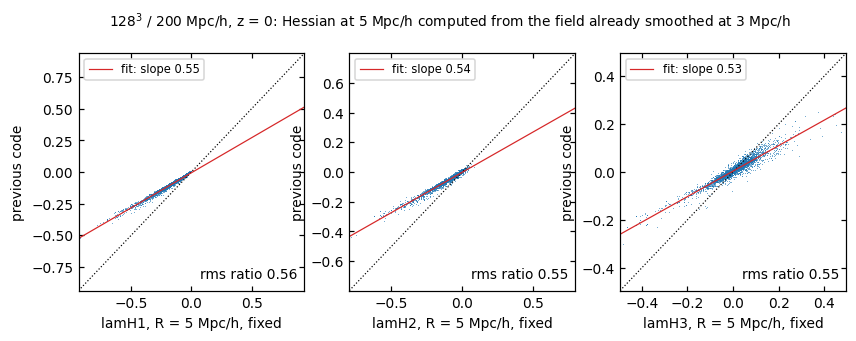

In [2]:
V = np.load('data/vahc_bug_128.npz')
fig, ax = plt.subplots(1, 3, figsize=(9, 2.8))
s = 2
for j, k in enumerate(['lamH1', 'lamH2', 'lamH3']):
    b, f = V[f'{k}_R5Mpch_buggy_{s}'], V[f'{k}_R5Mpch_fixed_{s}']
    ax[j].plot(f, b, ',', color='C0', alpha=0.6)
    lim = np.percentile(np.abs(f), 99.5); ax[j].plot([-lim, lim], [-lim, lim], 'k:', lw=0.8)
    p = np.polyfit(f, b, 1)
    ax[j].plot([-lim, lim], np.polyval(p, [-lim, lim]), 'C3', lw=0.8, label=f'fit: slope {p[0]:.2f}')
    ax[j].set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel=f'{k}, R = 5 Mpc/h, fixed', ylabel='previous code')
    ax[j].legend(loc='upper left')
    ax[j].text(0.97, 0.05, f'rms ratio {b.std() / f.std():.2f}', transform=ax[j].transAxes, ha='right')
fig.suptitle('128$^3$ / 200 Mpc/h, z = 0: Hessian at 5 Mpc/h computed from the field already smoothed at 3 Mpc/h', y=1.02, fontsize=9)
fig.savefig('figures/vahc_bug.pdf')
cols = V['columns']
for s in range(3):
    changed = [c for c, d in zip(cols, V[f'maxdiff_{s}']) if d > 0]
    print('snapshot', s, 'columns that differ:', changed, ' rms ratio:',
          [round(float(V[f'{c}_buggy_{s}'].std() / V[f'{c}_fixed_{s}'].std()), 3) for c in changed])

## Figure: per-particle quantization of `.pkc` (512^3, z = 0)

1342802 particles; position step 1.9531 kpc/h: max |dx| 0.9773, rms 0.5639 (uniform: 0.5638); velocity step 2.440: max |dv| 1.220, rms 0.704 (uniform: 0.704)


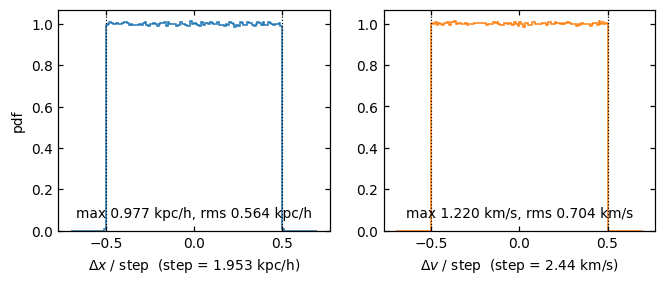

In [3]:
Q = np.load('data/quantization_512.npz')
st, vs = float(Q['pos_step_kpch']), float(Q['vel_step_kms'])
fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
hb = Q['hbins']; w_ = np.diff(hb)
ax[0].stairs(Q['hist_dx'] / Q['hist_dx'].sum() / w_, hb, color='C0')
ax[0].axvline(-0.5, color='k', ls=':', lw=0.8); ax[0].axvline(0.5, color='k', ls=':', lw=0.8)
ax[0].set(xlabel=f'$\\Delta x$ / step  (step = {st:.3f} kpc/h)', ylabel='pdf')
ax[1].stairs(Q['hist_dv'] / Q['hist_dv'].sum() / w_, hb, color='C1')
ax[1].axvline(-0.5, color='k', ls=':', lw=0.8); ax[1].axvline(0.5, color='k', ls=':', lw=0.8)
ax[1].set(xlabel=f'$\\Delta v$ / step  (step = {vs:.2f} km/s)')
mx, rx, mv, rv = Q['summary']
for a_, t in zip(ax, [f'max {mx:.3f} kpc/h, rms {rx:.3f} kpc/h', f'max {mv:.3f} km/s, rms {rv:.3f} km/s']):
    a_.text(0.5, 0.06, t, transform=a_.transAxes, ha='center')
fig.savefig('figures/quantization.pdf')
print(f"{int(Q['n_particles'])} particles; position step {st:.4f} kpc/h: max |dx| {mx:.4f}, rms {rx:.4f} "
      f"(uniform: {st/np.sqrt(12):.4f}); velocity step {vs:.3f}: max |dv| {mv:.3f}, rms {rv:.3f} (uniform: {vs/np.sqrt(12):.3f})")

## Figure: mass functions of the input routes and ratios to the raw-particle route

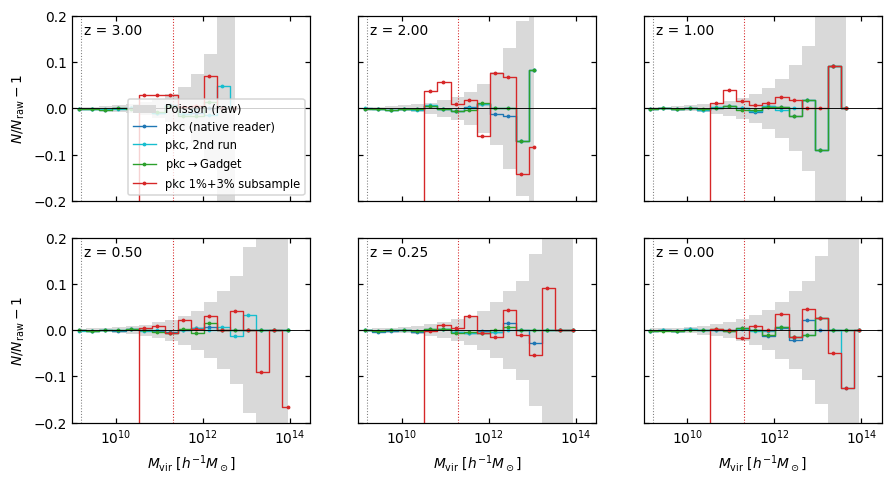

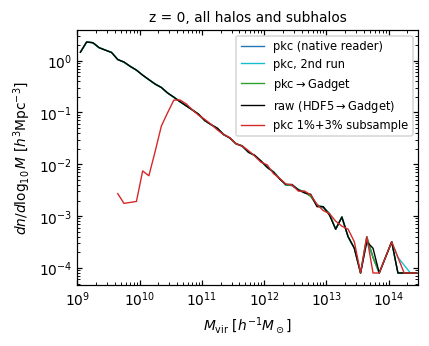

In [4]:
reb = lambda n: n.reshape(-1, 3).sum(1)            # 0.1 dex -> 0.3 dex bins
mc3 = np.sqrt(mb[:-1:3] * mb[3::3])
fig, ax = plt.subplots(2, 3, figsize=(9.5, 4.8), sharex=True, sharey=True)
for i in range(nz):
    a_ = ax.flat[i]; ref = reb(H[f'hm_h5g_{i}'].astype(float))
    ok = ref >= 5
    a_.fill_between(mc3[ok], -1 / np.sqrt(ref[ok]), 1 / np.sqrt(ref[ok]), color='0.85', lw=0, step='mid', label='Poisson (raw)')
    for r in ['pkc', 'pkc2', 'gad', 'pkcsub']:
        if f'hm_{r}_{i}' not in H: continue
        n = reb(H[f'hm_{r}_{i}'].astype(float))
        a_.plot(mc3[ok], n[ok] / ref[ok] - 1, color=C[r], label=LAB[r], ds='steps-mid', lw=0.9, marker='.', ms=3)
    a_.axhline(0, color='k', lw=0.6)
    a_.set_xscale('log'); a_.set_ylim(-0.2, 0.2); a_.text(0.05, 0.9, f'z = {z[i]:.2f}', transform=a_.transAxes)
    a_.axvline(20 * MP, color='0.5', ls=':', lw=0.7); a_.axvline(100 * 25 * MP, color='C3', ls=':', lw=0.7)
for a_ in ax[1]: a_.set_xlabel('$M_{\\rm vir}$ [$h^{-1}M_\\odot$]')
for a_ in ax[:, 0]: a_.set_ylabel('$N/N_{\\rm raw}-1$')
ax[0, 0].legend(loc='lower right', ncol=1); ax[0, 0].set_xlim(1e9, 3e14)
fig.savefig('figures/massfunction_ratio.pdf')

fig, ax = plt.subplots(figsize=(4, 3))
for r in routes:
    n = H[f'hm_{r}_{nz-1}'].astype(float); ok = n > 0
    ax.loglog(mc[ok], n[ok] / VOL / dlm, color=C[r], label=LAB[r], lw=0.9)
ax.set(xlabel='$M_{\\rm vir}$ [$h^{-1}M_\\odot$]', ylabel='$dn/d\\log_{10}M$ [$h^3$Mpc$^{-3}$]', xlim=(1e9, 3e14))
ax.legend(); ax.set_title('z = 0, all halos and subhalos', fontsize=9)
fig.savefig('figures/massfunction.pdf')

## Figure: matched-halo differences vs mass at z = 0

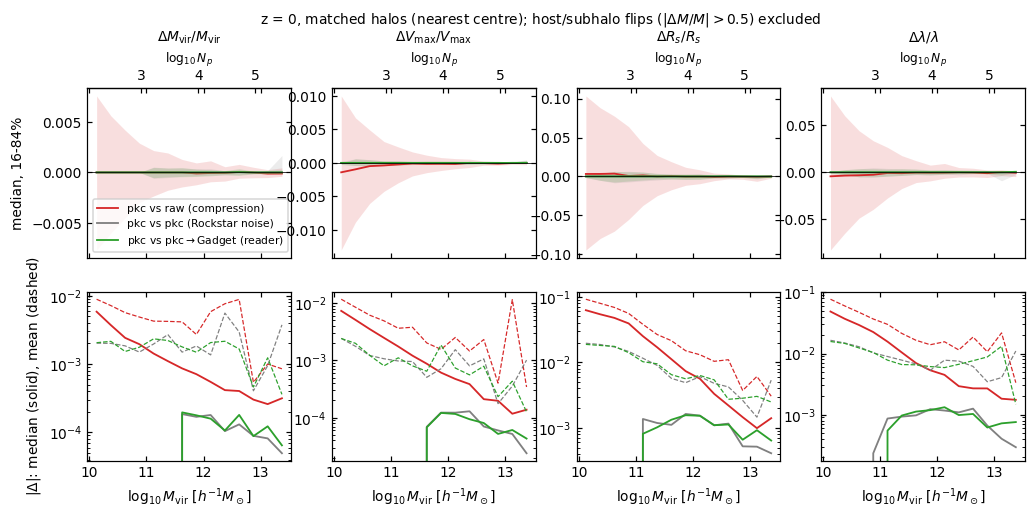

In [5]:
qs = [('dM', '$\\Delta M_{\\rm vir}/M_{\\rm vir}$'), ('dV', '$\\Delta V_{\\rm max}/V_{\\rm max}$'),
      ('dRs', '$\\Delta R_s/R_s$'), ('dSpin', '$\\Delta\\lambda/\\lambda$')]
def pairfig(i, pairs, fname, title):
    fig, ax = plt.subplots(2, 4, figsize=(11, 4.4), sharex=True)
    for (A, B) in pairs:
        P = pair(A, B, i)
        if P is None: continue
        lm = P['logM'].astype(float)
        for j, (k, lab) in enumerate(qs):
            d = P[k].astype(float); d[np.abs(d) > 0.5] = np.nan          # drop host/subhalo flips
            med = binned(lm, d, LB); lo = binned(lm, d, LB, lambda s: np.percentile(s, 16)); hi = binned(lm, d, LB, lambda s: np.percentile(s, 84))
            ax[0, j].plot(LC, med, color=PAIRC[A, B], label=PAIRLAB[A, B]); ax[0, j].fill_between(LC, lo, hi, color=PAIRC[A, B], alpha=0.15, lw=0)
            ax[1, j].semilogy(LC, binned(lm, np.abs(d), LB), color=PAIRC[A, B])
            ax[1, j].semilogy(LC, binned(lm, np.abs(d), LB, np.mean), color=PAIRC[A, B], ls='--', lw=0.8)
            ax[0, j].set_title(lab, fontsize=9)
    for j in range(4):
        ax[0, j].axhline(0, color='k', lw=0.5); ax[1, j].set_xlabel('$\\log_{10} M_{\\rm vir}$ [$h^{-1}M_\\odot$]')
        sec = ax[0, j].secondary_xaxis('top', functions=(lambda x: x - np.log10(MP), lambda x: x + np.log10(MP)))
        sec.set_xlabel('$\\log_{10} N_p$', fontsize=8)
    ax[0, 0].set_ylabel('median, 16-84%'); ax[1, 0].set_ylabel('$|\\Delta|$: median (solid), mean (dashed)')
    ax[0, 0].legend(loc='lower left', fontsize=7)
    fig.suptitle(title, y=1.04, fontsize=9); fig.savefig(fname)
pairfig(nz - 1, [('pkc', 'h5g'), ('pkc', 'pkc2'), ('pkc', 'gad')], 'figures/matched_z0.pdf',
        'z = 0, matched halos (nearest centre); host/subhalo flips ($|\\Delta M/M|>0.5$) excluded')

## Figure: redshift dependence of the compression effect

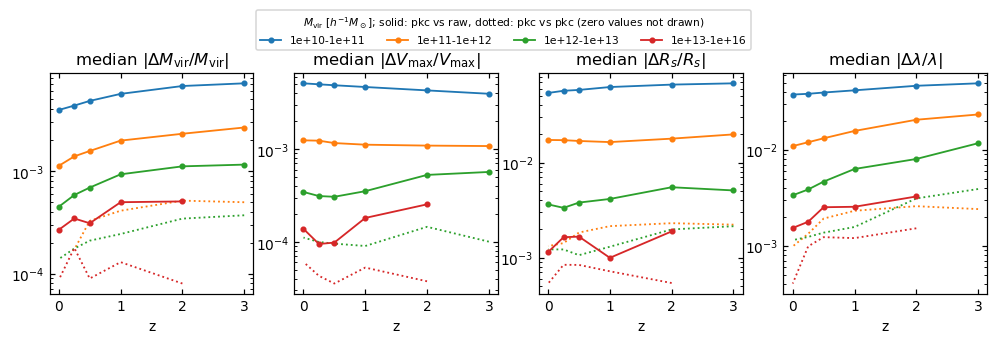

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(11, 2.6), sharex=True)
for j, (k, lab) in enumerate(qs):
    for b, (lo, hi) in enumerate(MBIN):
        for (A, B), ls in ((('pkc', 'h5g'), '-'), (('pkc', 'pkc2'), ':')):
            v = []
            for i in range(nz):
                P = pair(A, B, i); m = (P['logM'] >= np.log10(lo)) & (P['logM'] < np.log10(hi))
                d = P[k][m].astype(float); d = d[np.isfinite(d) & (np.abs(d) < 0.5)]
                v.append(np.median(np.abs(d)) if len(d) >= 5 else np.nan)
            v = np.where(np.array(v) > 0, v, np.nan)
            ax[j].semilogy(z, v, ls, color=f'C{b}', marker='o' if ls == '-' else None, ms=3,
                           label=f'{lo:.0e}-{hi:.0e}' if (ls == '-' and j == 0) else None)
    ax[j].set(xlabel='z', title='median $|$' + lab + '$|$'); ax[j].invert_xaxis()
fig.legend(*ax[0].get_legend_handles_labels(), loc='upper center', ncol=4, fontsize=7, bbox_to_anchor=(0.5, 1.12),
           title='$M_{\\rm vir}$ [$h^{-1}M_\\odot$]; solid: pkc vs raw, dotted: pkc vs pkc (zero values not drawn)', title_fontsize=7)
fig.savefig('figures/redshift_dependence.pdf')

## Figure: centre and bulk-velocity offsets

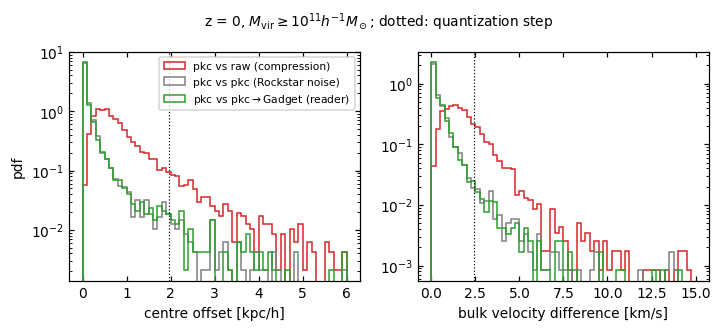

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(7.5, 2.7))
i = nz - 1
for (A, B) in [('pkc', 'h5g'), ('pkc', 'pkc2'), ('pkc', 'gad')]:
    P = pair(A, B, i); m = P['matched'] & (P['logM'] >= 11)
    ax[0].hist(P['dpos'][m], bins=np.linspace(0, 6, 61), histtype='step', density=True, color=PAIRC[A, B], label=PAIRLAB[A, B])
    ax[1].hist(P['dvel'][m], bins=np.linspace(0, 15, 61), histtype='step', density=True, color=PAIRC[A, B])
ax[0].axvline(float(Q['pos_step_kpch']), color='k', ls=':', lw=0.8); ax[1].axvline(float(Q['vel_step_kms']), color='k', ls=':', lw=0.8)
ax[0].set(xlabel='centre offset [kpc/h]', ylabel='pdf', yscale='log'); ax[1].set(xlabel='bulk velocity difference [km/s]', yscale='log')
ax[0].legend(fontsize=7); fig.suptitle('z = 0, $M_{\\rm vir} \\geq 10^{11}h^{-1}M_\\odot$; dotted: quantization step', y=1.02, fontsize=9)
fig.savefig('figures/offsets.pdf')

## Figure: halo finding on the 1% + 3% subsample (`PKC_SUBSAMPLES = "1,3"`)

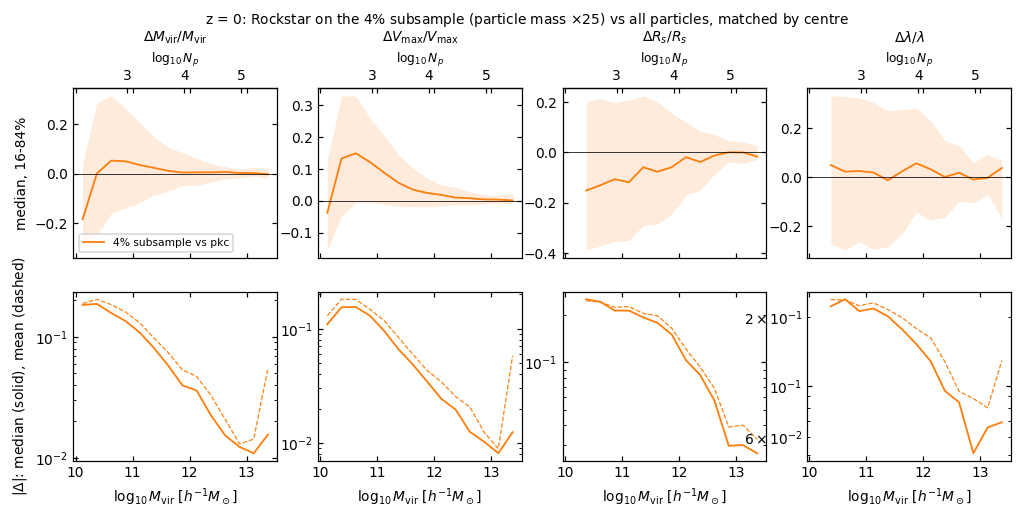

In [8]:
if pair('pkcsub', 'pkc', nz - 1) is not None:
    pairfig(nz - 1, [('pkcsub', 'pkc')], 'figures/subsample_z0.pdf',
            'z = 0: Rockstar on the 4% subsample (particle mass $\\times$25) vs all particles, matched by centre')
else:
    print('no subsample route in the data')

## Figure: consistent-trees z = 0 (pkc vs raw)

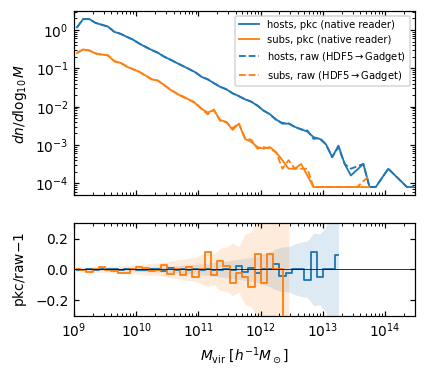

In [9]:
T = np.load('data/ctrees_512.npz')
if 'host_pkc' in T:
    fig, ax = plt.subplots(2, 1, figsize=(4, 3.6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    for r, ls in (('pkc', '-'), ('h5g', '--')):
        for kind, c in (('host', 'C0'), ('sub', 'C1')):
            n = T[f'{kind}_{r}'].astype(float); ok = n > 0
            ax[0].loglog(mc[ok], n[ok] / VOL / dlm, ls, color=c, label=f'{kind}s, {LAB[r]}')
    for kind, c in (('host', 'C0'), ('sub', 'C1')):
        a, b = T[f'{kind}_pkc'].astype(float), T[f'{kind}_h5g'].astype(float); ok = b >= 5
        ax[1].plot(mc[ok], a[ok] / b[ok] - 1, color=c, ds='steps-mid'); ax[1].fill_between(mc[ok], -1/np.sqrt(b[ok]), 1/np.sqrt(b[ok]), color=c, alpha=0.15, lw=0)
    ax[1].axhline(0, color='k', lw=0.5); ax[1].set(ylim=(-0.3, 0.3), xlabel='$M_{\\rm vir}$ [$h^{-1}M_\\odot$]', ylabel='pkc/raw$-1$')
    ax[0].set(ylabel='$dn/d\\log_{10}M$', xlim=(1e9, 3e14)); ax[0].legend(fontsize=6.5)
    fig.savefig('figures/ctrees_z0.pdf')

## Figures: wall time and peak memory

    run    stage     job  wall_s  pss_gb  nproc  rss_gb  maxrss_single_gb  o
lcdm512      sim 2536502  4780.0   25.09      4   25.10         24.988029  0
lcdm512 rockstar 2536503   475.0    8.03     27    8.22          0.442005  1
lcdm512   ctrees 2536504   506.0    0.80      9    0.91               NaN  2
lcdm512     vahc 2536505  3666.0   91.56      9   91.74         25.464821  3
lcdm512     fits 2536506   153.0    5.90      2    5.90               NaN  4
 mem128      sim 2536497   110.0    5.86      4    5.88          5.799423  0
 mem128 rockstar 2536498    41.0    0.20     27    0.38          0.020187  1
 mem128   ctrees 2536499     9.0    0.00      2    0.01               NaN  2
 mem128     vahc 2536500    49.0    2.29     10    2.52          0.579353  3
 mem128     fits 2536501     6.0    0.10      2    0.11               NaN  4
             route  exit  wall_s                                            halos  pss_gb  nproc  rss_gb
               pkc     0     803        315112 3

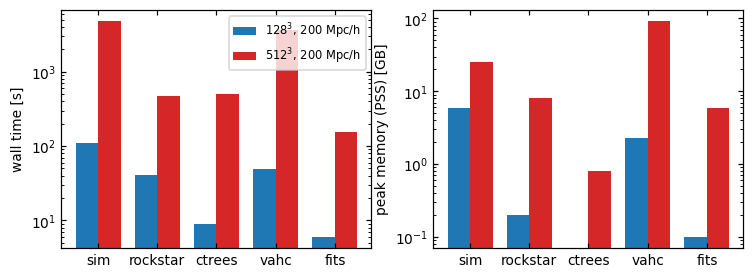

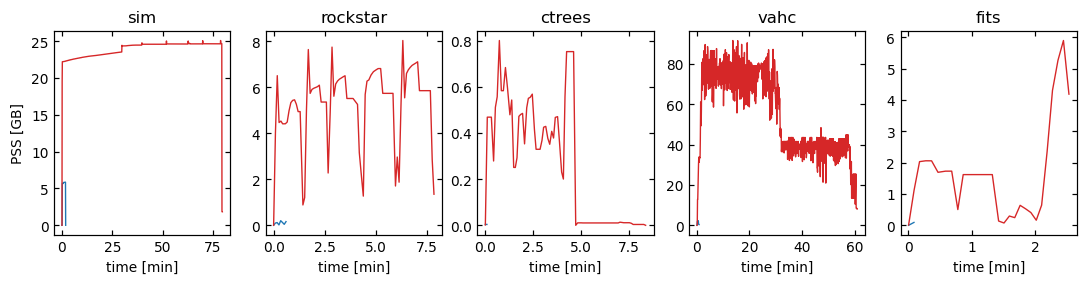

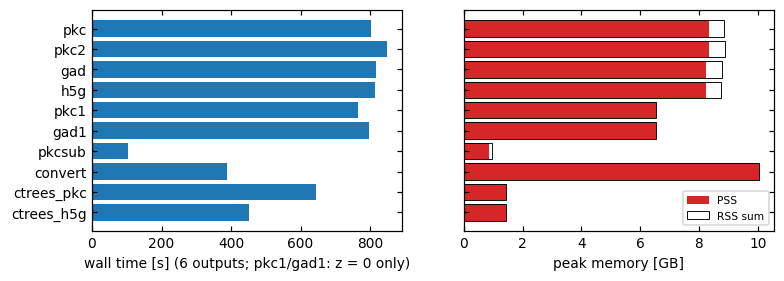

In [10]:
S = pd.read_csv('data/stages.csv'); R = pd.read_csv('data/routes_512.csv')
order = ['sim', 'rockstar', 'ctrees', 'vahc', 'fits']
S['o'] = S.stage.map({s: i for i, s in enumerate(order)}); S = S.sort_values(['run', 'o', 'job']).drop_duplicates(['run', 'stage'], keep='last')
print(S.to_string(index=False)); print(R.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
w = 0.38
for k, (run, c) in enumerate((('mem128', 'C0'), ('lcdm512', 'C3'))):
    s = S[S.run == run].set_index('stage').reindex(order)
    x = np.arange(len(order)) + (k - 0.5) * w
    ax[0].bar(x, s.wall_s, w, color=c, label={'mem128': '128$^3$, 200 Mpc/h', 'lcdm512': '512$^3$, 200 Mpc/h'}[run])
    ax[1].bar(x, s.pss_gb, w, color=c)
for a_ in ax: a_.set_xticks(range(len(order))); a_.set_xticklabels(order); a_.set_yscale('log')
ax[0].set_ylabel('wall time [s]'); ax[1].set_ylabel('peak memory (PSS) [GB]'); ax[0].legend()
fig.savefig('figures/stages_resources.pdf')

fig, ax = plt.subplots(1, 5, figsize=(12, 2.4))
for j, st_ in enumerate(order):
    for run, c in (('mem128', 'C0'), ('lcdm512', 'C3')):
        f = f'data/mem_{run}_{st_}.tsv'
        if not os.path.exists(f): continue
        d = np.loadtxt(f, comments='#', ndmin=2)
        if len(d) == 0: continue
        ax[j].plot(d[:, 0] / 60, d[:, 2] / 1048576, color=c, lw=0.9)
    ax[j].set(title=st_, xlabel='time [min]'); ax[0].set_ylabel('PSS [GB]')
fig.savefig('figures/memory_timeline.pdf')

rr = R[R.route.isin(['pkc', 'pkc2', 'gad', 'h5g', 'pkcsub', 'pkc1', 'gad1', 'convert', 'ctrees_pkc', 'ctrees_h5g'])]
fig, ax = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
ax[0].barh(rr.route, rr.wall_s, color='C0'); ax[0].set_xlabel('wall time [s] (6 outputs; pkc1/gad1: z = 0 only)')
ax[1].barh(rr.route, rr.pss_gb, color='C3', label='PSS'); ax[1].barh(rr.route, rr.rss_gb, fill=False, edgecolor='k', lw=0.6, label='RSS sum')
ax[1].set_xlabel('peak memory [GB]'); ax[1].legend(fontsize=7); ax[0].invert_yaxis(); ax[1].tick_params(labelleft=False)
fig.savefig('figures/routes_resources.pdf')

## Tables for the report (`figures/tab_*.tex`)

In [11]:
def stats(A, B, i, lo, hi):
    P = pair(A, B, i); m = (P['logM'] >= np.log10(lo)) & (P['logM'] < np.log10(hi)); ok = P['matched'][m]
    d = {k: P[k][m][ok].astype(float) for k in ('dM', 'dV', 'dRs', 'dSpin', 'dpos', 'dvel')}
    flip = np.abs(d['dM']) > 0.5; g = ~flip
    na, nb = int(H[f'hm_{A}_{i}'][(mc >= lo) & (mc < hi)].sum()), int(H[f'hm_{B}_{i}'][(mc >= lo) & (mc < hi)].sum())
    return dict(n=na, nb=nb, dn=na / nb - 1, pois=1 / np.sqrt(nb), match=ok.mean(), flip=flip.mean(),
                dM=np.median(d['dM'][g]), adM=np.median(np.abs(d['dM'][g])), adV=np.median(np.abs(d['dV'][g])),
                dpos=np.median(d['dpos'][g]), dvel=np.median(d['dvel'][g]), aRs=np.median(np.abs(d['dRs'][g])),
                Rs=np.median(d['dRs'][g]), aSp=np.median(np.abs(d['dSpin'][g])), Sp=np.median(d['dSpin'][g]))
def e(x): return '0' if x == 0 else f'{x:.1e}'.replace('e-0', 'e-').replace('e+0', 'e')
lines = []
for (lo, hi) in MBIN:
    a, b = stats('pkc', 'h5g', nz - 1, lo, hi), stats('pkc', 'pkc2', nz - 1, lo, hi)
    lines.append(f"${np.log10(lo):.0f}$--${np.log10(min(hi, 1e15)):.0f}$ & {a['n']} & {100*a['dn']:+.2f} ({100*a['pois']:.1f}) & "
                 f"{100*a['match']:.2f} ({100*b['match']:.2f}) & {100*a['flip']:.1f} ({100*b['flip']:.1f}) & {e(a['dM'])} & "
                 f"{e(a['adM'])} ({e(b['adM'])}) & {e(a['adV'])} ({e(b['adV'])}) & {a['dpos']:.2f} ({b['dpos']:.2f}) & "
                 f"{100*a['aRs']:.2f} ({100*b['aRs']:.2f}), {100*a['Rs']:+.2f} & {100*a['aSp']:.2f} ({100*b['aSp']:.2f}), {100*a['Sp']:+.2f} \\\\")
open('figures/tab_compression_z0.tex', 'w').write('\n'.join(lines) + '\n'); print('\n'.join(lines))

lines = []
for _, r in S.iterrows():
    lines.append(f"{'128$^3$' if r.run == 'mem128' else '512$^3$'} & {r.stage} & {r.wall_s:.0f} & {r.pss_gb:.2f} & {r.rss_gb:.2f} & {int(r.nproc)} \\\\")
open('figures/tab_stages.tex', 'w').write('\n'.join(lines) + '\n'); print('\n'.join(lines))
lines = []
for _, r in R.iterrows():
    if r.route.startswith('exact'): continue
    nh = r.halos.split()[-1] if isinstance(r.halos, str) and r.halos.strip() else '--'
    lines.append(f"{r.route.replace('_', ' ')} & {r.wall_s:.0f} & {r.pss_gb:.2f} & {r.rss_gb:.2f} & {nh} \\\\")
open('figures/tab_routes.tex', 'w').write('\n'.join(lines) + '\n'); print('\n'.join(lines))

$10$--$11$ & 31764 & -0.00 (0.6) & 99.50 (99.92) & 0.9 (0.2) & 0 & 3.9e-3 (0) & 5.1e-3 (0) & 0.86 (0.00) & 5.52 (0.00), +0.42 & 3.80 (0.00), -0.31 \\
$11$--$12$ & 4213 & -0.12 (1.5) & 99.69 (99.93) & 1.3 (0.2) & 0 & 1.1e-3 (0) & 1.2e-3 (6.0e-5) & 0.64 (0.03) & 1.73 (0.13), +0.07 & 1.09 (0.10), -0.06 \\
$12$--$13$ & 510 & -0.20 (4.4) & 99.80 (100.00) & 3.9 (1.0) & 0 & 4.5e-4 (1.4e-4) & 3.4e-4 (1.1e-4) & 0.66 (0.16) & 0.36 (0.12), -0.02 & 0.33 (0.11), -0.04 \\
$13$--$15$ & 57 & +1.79 (13.4) & 100.00 (100.00) & 5.3 (1.8) & -7.7e-5 & 2.7e-4 (8.7e-5) & 1.3e-4 (5.7e-5) & 0.87 (0.33) & 0.11 (0.05), -0.03 & 0.15 (0.04), -0.01 \\
512$^3$ & sim & 4780 & 25.09 & 25.10 & 4 \\
512$^3$ & rockstar & 475 & 8.03 & 8.22 & 27 \\
512$^3$ & ctrees & 506 & 0.80 & 0.91 & 9 \\
512$^3$ & vahc & 3666 & 91.56 & 91.74 & 9 \\
512$^3$ & fits & 153 & 5.90 & 5.90 & 2 \\
128$^3$ & sim & 110 & 5.86 & 5.88 & 4 \\
128$^3$ & rockstar & 41 & 0.20 & 0.38 & 27 \\
128$^3$ & ctrees & 9 & 0.00 & 0.01 & 2 \\
128$^3$ & vahc & 49 